In [1]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np
import random
import torch

In [2]:
# set seeds 
np.random.seed(6)
torch.manual_seed(6)
random.seed(6)

work_folder = 'edge_spen'
saving_folder = 'l6'

In [3]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Splite resto in attesa di una sua rispostae resto in attesa di una sua risposta the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [4]:
os.chdir(work_folder)

In [5]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../")))
from ants_move import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

pygame 2.6.0 (SDL 2.28.4, Python 3.8.2)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [6]:
file_path = saving_folder + '/' + 'parameters.txt'  # Path to the parameters file

parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 300
Lx = 32
Ly = 32
delta = 0.3
beta = 4.5
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
t_transient = 200
tmax = 1200
batch_size = 60
gamma = 0.99
state_dim = (4, 9, 9)
action_dim = 8
action_bound = 1
vision = 9
actor_lr = 5e-06
critic_lr = 5e-05
weight_decay = 0.0
clip_epsilon = 0.2
entropy_coeff = 0.05
policy_steps = 1000
learning_steps = 1
clip_grad = False
use_gae = True
lam = 0.95


In [7]:
norm_advantages = False

In [8]:
env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision=state_dim[-1])

In [9]:
from ppo_ants import *
config_net_file = f"{saving_folder}/networks.yaml"
ppo_ants = PPO_ants(env,
                 gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay, config_net_file,
                 clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                 state_dim, action_dim, clip_grad=clip_grad,
                 use_gae=use_gae, lam=lam, norm_advantages=norm_advantages)        

In [10]:
ppo_ants.setup_networks()

if not os.path.exists(saving_folder + '/results'):
    os.makedirs(saving_folder + '/results')

if not os.path.exists(saving_folder + '/results_test'):
    os.makedirs(saving_folder + '/results_test')

if not os.path.exists(saving_folder + '/weights'):
    os.makedirs(saving_folder + '/weights')

with open(saving_folder + '/results/results.txt', 'w') as file:
    file.write(f"")

with open(saving_folder + '/results/reward.txt', 'w') as file:
    file.write(f"")
    
'''with open(saving_folder + '/results/op.txt', 'w') as file:
    file.write(f"")'''
    
with open(saving_folder + '/results_test/reward.txt', 'w') as file:
    file.write(f"")

'''with open(saving_folder + '/results_test/op.txt', 'w') as file:
    file.write(f"")'''

with open(saving_folder + '/results/actor_weights.txt', 'w') as file:
    file.write(f"")

with open(saving_folder + '/results/critic_weights.txt', 'w') as file:
    file.write(f"")

In [11]:
ppo_ants.setup_networks()
print(ppo_ants.actor)

CNN_actor(
  (cnn_layers): Sequential(
    (0): Conv2d(4, 32, kernel_size=(3, 3), stride=(1, 1), padding=valid)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=valid)
    (5): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.0, inplace=False)
  )
  (dense_layers): Sequential(
    (0): Linear(in_features=400, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=128, out_features=8, bias=True)
    (7): Identity()
  )
)


(array([3743., 3796., 3909., 3698., 3784., 3658., 3656., 3756.]),
 array([0, 1, 2, 3, 4, 5, 6, 7, 8]),
 <BarContainer object of 8 artists>)

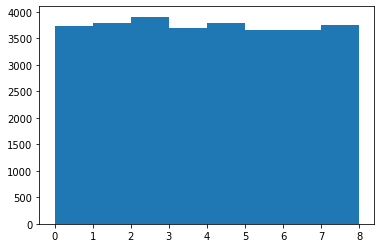

In [12]:
plt.hist(ppo_ants.policy(torch.FloatTensor(np.random.uniform(0,1,(30000,4,vision,vision)))), bins=np.arange(0,9))

In [13]:
cw = ppo_ants.compute_critic_weights()
indx_w_critic = []

for i in range(len(cw)):
    try:
        cw[i].numpy().shape[1]
        indx_w_critic.append(i)
    except:
        pass

aw = ppo_ants.compute_actor_weights()
indx_w_actor = []

for i in range(len(aw)):
    try:
        aw[i].numpy().shape[1]
        indx_w_actor.append(i)
    except:
        pass

In [14]:
print(str([cw[i].numpy().mean() for i in indx_w_critic]))

[-0.003109311, -0.00069449254, 7.518524e-05, -0.00010774767, 0.0015231757]


In [15]:
print(str([aw[i].numpy().mean() for i in indx_w_actor]))

[0.0006765274, -0.00034440644, -0.00012386276, 0.00013260546, 0.0008068477]


In [16]:
epi = 1

In [17]:
with open(saving_folder + '/results/critic_weights.txt', 'a') as f:
    f.write(str([cw[i].numpy().mean() for i in indx_w_critic]) + '\n')
        
with open(saving_folder + '/results/actor_weights.txt', 'a') as f:
    f.write(str([aw[i].numpy().mean() for i in indx_w_actor]) + '\n')

In [18]:
best_score = -np.inf
N_epi = 2000

In [ ]:
while epi < N_epi:
        
    score, act = ppo_ants.training_episode()

    if epi %1 == 0:

        avg_score = np.mean(score)
        avg_a = np.mean(act)
        final_op = ppo_ants.env.order_parameter_p().copy()
        final_op_s = ppo_ants.env.order_parameter_s().copy()
        
        if epi %10 == 0:
                
            score_test, act_test = ppo_ants.test_episode()
                
            with open(saving_folder + '/results/reward.txt', 'a') as file:
                for item in score:
                    file.write(f"{item}\n")

            with open(saving_folder + '/results_test/reward.txt', 'a') as file:
                for item in score_test:
                    file.write(f"{np.mean(item)}\n")

        cw = ppo_ants.compute_critic_weights()
        aw = ppo_ants.compute_actor_weights()

        with open(saving_folder + '/results/critic_weights.txt', 'a') as f:
            f.write(str([cw[i].numpy().mean() for i in indx_w_critic]) + '\n')
        
        with open(saving_folder + '/results/actor_weights.txt', 'a') as f:
            f.write(str([aw[i].numpy().mean() for i in indx_w_actor]) + '\n')

        ppo_ants.save_weights(saving_folder + '/weights')

    
    with open(saving_folder + '/results/results.txt', 'a') as f:
                    
        f.write(str(epi) + ' '  + str(avg_score) + ' ' + str(avg_a) + ' ' + str(final_op) + ' ' + str(final_op_s) + '\n')

    epi += 1 
    print('epi: ', epi, 'score: ', np.mean(score), end='\r')

    if np.mean(score) > best_score:
        best_score = np.mean(score)
        ppo_ants.save_weights(saving_folder + '/weights/best_weights')
        print('New best score: ', best_score, end='\r')